In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn.preprocessing import StandardScaler
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

# continuous_features = feature_columns
continuous_features =  ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
continuous_features = [col for col in continuous_features if col in feature_columns]

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1825

In [4]:
from sklearn.preprocessing import MinMaxScaler

# Prepare features and target
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

continuous_features_indices = [data_x.columns.get_loc(col) for col in continuous_features]

# Scale features
scaler = MinMaxScaler()
# Scale only continuous features, keep others as-is
data_x_scaled = data_x.copy()
data_x_scaled.iloc[:, continuous_features_indices] = scaler.fit_transform(data_x.iloc[:, continuous_features_indices])

print("Data prepared for Cox model")

Data prepared for Cox model


In [5]:
# Check correlation matrix to identify highly correlated features
import seaborn as sns

corr_matrix = data_x_scaled.corr()
high_corr = []

for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

if high_corr:
    print(f"Found {len(high_corr)} highly correlated pairs (|r| > 0.9):")
    for feat1, feat2, corr in high_corr:
        print(f"  {feat1} <-> {feat2}: {corr:.3f}")
else:
    print("No highly correlated features found (|r| > 0.9)")

No highly correlated features found (|r| > 0.9)


In [6]:
# Prepare data for lifelines (requires DataFrame format)
df_cox = data_x_scaled.copy()
df_cox['event'] = survival_dataset['Regional LN recurrence'].values
df_cox['time'] = survival_dataset['Survival days'].values

# NOTE: this fit is for the correlation/VIF exploration below only -- it is NOT
# used for the PH test. It has 30 raw covariates against only ~27 events
# (EPV < 1) and VIFs as high as ~42 (see VIF section further down), so its
# coefficient standard errors are badly inflated by collinearity and small
# sample size. Fit with L2 regularization just to keep the (near-singular)
# information matrix invertible.
cph = CoxPHFitter(penalizer=0.1)  # Start with 0.1, adjust if needed
cph.fit(df_cox, duration_col='time', event_col='event')

print("Cox model fitted successfully")
print(f"Concordance index: {cph.concordance_index_:.4f}")
print(f"Penalizer: {cph.penalizer}")
print(f"Number of features: {len(cph.params_)}")
print(f"Events: {int(df_cox['event'].sum())} / {len(df_cox)}  "
      f"(EPV = {df_cox['event'].sum() / len(cph.params_):.2f})")

Cox model fitted successfully
Concordance index: 0.9041
Penalizer: 0.1
Number of features: 30
Events: 27 / 3228  (EPV = 0.90)


## Test proportional hazards assumption

`proportional_hazard_test` regresses each covariate's scaled Schoenfeld
residuals on transformed event time. Its test-statistic denominator is
`n_deaths * SE(beta)^2 * ...`, so it's mechanically attenuated (shrunk toward 0,
p pushed toward 1) by anything that inflates `SE(beta)`: a weak penalizer, severe
multicollinearity, or too few events per covariate.

**That's why the earlier result (global χ² = 5.03 on df = 30, p = 1.00) wasn't
credible.** It came from `cph`, the diagnostic fit above: 30 raw covariates
against only 27 events (EPV ≈ 0.9, well below the ~10 EPV rule of thumb) and VIFs up
to ~42 (see the VIF section below). Neither of those zeroes out coefficients
under lifelines' L2 `penalizer` (none of the 30 coefficients in `cph.params_` are
actually 0), but both inflate `SE(beta)` enough to drag every Schoenfeld statistic,
and their sum, well below what they'd be under a well-specified model.

Also just the wrong model to test in the first place: the production 5-year Cox model
(`new_approaches/models/5y/cox.ipynb`) is a LASSO-penalized `CoxnetSurvivalAnalysis`
(`l1_ratio=1.0`, `alpha=0.000853168`) that keeps only **9 of the 30 terms non-zero**
(21 shrunk to exactly 0 and dropped). That's the model whose PH assumption actually
matters, and it should be checked **unpenalized**, since the L1 penalty biases
coefficients toward 0 for variable selection, and we don't want that carrying into
a residual-based diagnostic.

The cells below refit those 9 retained terms without penalization and run the PH
test against that fit. Null hypothesis: no correlation between scaled Schoenfeld
residuals and time (PH holds). p > 0.05 -> holds, p < 0.05 -> violated.

In [7]:
# The production 5-year Cox model (models/5y/cox.ipynb) is a LASSO-penalized
# CoxnetSurvivalAnalysis (l1_ratio=1.0, alpha=0.000853168) refit on the full
# dataset; these are its 9 non-zero terms. Keep this list in sync with that
# notebook's coefficient table if the production model changes.
retained_terms = [
    "Oestrogen receptor status at CB",
    "Neoadjuvant (Only) therapy with biological drugs",
    "Radiotherapy (RT) performed",
    "Isotype at CB_4.0",
    "Radiotherapy on supraclavicular area",
    "Grade at CB_3.0",
    "Adjuvant therapy using biological drugs",
    "Side location of the lesion",
    "Treatment in association with chemotherapy",
]

### Univariate pre-selection screen (all 30 candidates)

Coxnet's partial likelihood assumes proportional hazards when it estimates
coefficients. If one of the 21 dropped variables actually has a strong but
*time-varying* effect (protective early, harmful later, say), a PH-constrained
fit can average that out to something small and unpenalized away - it would
never get a hearing in the 9-term test below, which only looks at survivors of
that same PH-constrained selection.

To check for that: fit one **unpenalized, single-covariate** Cox model per
candidate variable and run the Schoenfeld test on each. Sidesteps both problems
with the earlier 30-covariate joint fit, since EPV is now 27 events / 1 term
per model, and there's no collinearity between covariates because each is
tested alone.

Caveat: a few binary covariates have **zero events in one level** (complete
separation) - their coefficient runs off toward +-infinity and the resulting
"p ≈ 1" is degenerate, not evidence that PH holds. Flagged and excluded from
the violation summary below rather than counted as passes.

In [8]:
from lifelines.exceptions import ConvergenceError

univariate_results = []
for feature in feature_columns:
    df_uni = df_cox[[feature, 'time', 'event']].copy()

    # Unpenalized is preferred; some rare/sparse-event covariates hit
    # quasi-complete separation univariately (no other covariates in the fit
    # to stabilize it) and need a token penalizer just to converge.
    # `penalizer_used` in the output table below flags which ones needed it.
    needed_penalizer = 0.0
    cph_uni = CoxPHFitter(penalizer=0.0)
    try:
        cph_uni.fit(df_uni, duration_col='time', event_col='event')
    except ConvergenceError:
        needed_penalizer = 0.001
        cph_uni = CoxPHFitter(penalizer=needed_penalizer)
        cph_uni.fit(df_uni, duration_col='time', event_col='event')

    # Complete separation flag: for a binary covariate, if one level has zero
    # events, the coefficient runs off toward +-inf and the "no PH violation"
    # p-value the test reports is degenerate, not evidence of anything.
    complete_separation = False
    unique_vals = df_uni[feature].dropna().unique()
    if set(unique_vals) <= {0, 1} and len(unique_vals) > 1:
        events_by_level = df_uni.groupby(feature)['event'].sum()
        complete_separation = bool((events_by_level == 0).any())

    ph_uni = proportional_hazard_test(cph_uni, df_uni, time_transform='rank')
    univariate_results.append({
        'feature': feature,
        'retained_in_production_model': feature in retained_terms,
        'penalizer_used': needed_penalizer,
        'complete_separation': complete_separation,
        'univariate_coef': cph_uni.params_[feature],
        'ph_test_statistic': ph_uni.summary.loc[feature, 'test_statistic'],
        'ph_p_value': ph_uni.summary.loc[feature, 'p'],
    })

univariate_df = pd.DataFrame(univariate_results).sort_values('ph_p_value').reset_index(drop=True)
print(univariate_df.to_string(index=False))

n_separated = univariate_df['complete_separation'].sum()
if n_separated > 0:
    print(f"\n⚠️  {n_separated} variable(s) have zero events in one level (complete "
          f"separation) -- their coefficient and PH p-value above are degenerate, not")
    print("   evidence that PH holds for them:")
    print(univariate_df.loc[univariate_df['complete_separation'], ['feature', 'univariate_coef', 'ph_p_value']]
          .to_string(index=False))

testable = univariate_df[~univariate_df['complete_separation']]
dropped_violations = testable[
    ~testable['retained_in_production_model'] & (testable['ph_p_value'] < 0.05)
]

print()
if len(dropped_violations) > 0:
    print(f"⚠️  {len(dropped_violations)} testable variable(s) NOT in the production model "
          f"show a univariate PH violation (p < 0.05):")
    print(dropped_violations[['feature', 'univariate_coef', 'ph_p_value']].to_string(index=False))
    print("\nThese may have a real, time-varying effect that Coxnet's PH-constrained")
    print("selection could have undersold -- worth a closer look before treating their")
    print("absence from the 9-term model as 'no effect'.")
else:
    print("✓ None of the testable variables dropped by the production model show a "
          "univariate PH violation.")
    print("  Coxnet's PH-constrained selection does not appear to have discarded a term")
    print("  with a hidden, strongly time-varying effect.")

                                                  feature  retained_in_production_model  penalizer_used  complete_separation  univariate_coef  ph_test_statistic  ph_p_value
                                          Grade at CB_2.0                         False           0.000                False        -0.904724       1.300544e+01    0.000311
                       Progesterone receptor status at CB                         False           0.000                False        -1.923551       9.134292e+00    0.002509
                                          Grade at CB_3.0                          True           0.000                False         1.310516       5.846246e+00    0.015610
                          Oestrogen receptor status at CB                          True           0.000                False        -2.535519       5.702289e+00    0.016943
         Neoadjuvant (Only) therapy with biological drugs                          True           0.001                False         2.

In [9]:
# retained_terms was defined above (production model's 9 non-zero terms)
df_retained = df_cox[retained_terms + ['time', 'event']].copy()
print(f"Events: {int(df_retained['event'].sum())}, terms: {len(retained_terms)}, "
      f"EPV: {df_retained['event'].sum() / len(retained_terms):.2f}")

# VIF among the retained terms only, to check whether the collinearity problem
# seen across all 30 raw covariates (VIF up to ~42) survives variable selection.
vif_retained = pd.DataFrame({
    "feature": retained_terms,
    "VIF": [variance_inflation_factor(df_retained[retained_terms].values, i)
            for i in range(len(retained_terms))]
}).sort_values("VIF", ascending=False)
print("\nVIF among the 9 retained terms:")
print(vif_retained.to_string(index=False))

# Unpenalized refit over the retained terms only -- this is the fit the PH
# test should run against.
cph_retained = CoxPHFitter(penalizer=0.0)
cph_retained.fit(df_retained, duration_col='time', event_col='event')
print(f"\nUnpenalized concordance (9 retained terms): {cph_retained.concordance_index_:.4f}")

# Test proportional hazards assumption
ph_test_result = proportional_hazard_test(cph_retained, df_retained, time_transform='rank')

print("\n=== PROPORTIONAL HAZARDS ASSUMPTION TEST (unpenalized, 9 retained terms) ===")
print("\nTest statistics for each term:")

# Get the summary DataFrame
ph_test_results = ph_test_result.summary

print(ph_test_results)

# Identify terms that violate the PH assumption (p < 0.05)
violations = ph_test_results[ph_test_results['p'] < 0.05]

if len(violations) > 0:
    print(f"\n⚠️  WARNING: {len(violations)} terms violate the PH assumption (p < 0.05):")
    print(violations[['test_statistic', 'p']].sort_values('p'))
else:
    print("\n✓ All terms satisfy the PH assumption (p > 0.05)")

# Summary statistics
print(f"\nSummary:")
print(f"  - Total terms tested: {len(ph_test_results)}")
print(f"  - Terms violating PH (p < 0.05): {len(violations)}")
print(f"  - Percentage violating: {100 * len(violations) / len(ph_test_results):.1f}%")

Events: 27, terms: 9, EPV: 3.00

VIF among the 9 retained terms:
                                         feature      VIF
                 Oestrogen receptor status at CB 4.709163
                     Radiotherapy (RT) performed 4.669637
      Treatment in association with chemotherapy 2.089749
                     Side location of the lesion 1.809195
            Radiotherapy on supraclavicular area 1.417357
                                 Grade at CB_3.0 1.361641
                               Isotype at CB_4.0 1.267217
         Adjuvant therapy using biological drugs 1.225683
Neoadjuvant (Only) therapy with biological drugs 1.108542



Unpenalized concordance (9 retained terms): 0.9196

=== PROPORTIONAL HAZARDS ASSUMPTION TEST (unpenalized, 9 retained terms) ===

Test statistics for each term:
                                                  test_statistic         p  \
Adjuvant therapy using biological drugs                 0.663233  0.415421   
Grade at CB_3.0                                         6.357498  0.011689   
Isotype at CB_4.0                                       0.030051  0.862376   
Neoadjuvant (Only) therapy with biological drugs        4.400029  0.035938   
Oestrogen receptor status at CB                         3.683115  0.054966   
Radiotherapy (RT) performed                             1.251157  0.263332   
Radiotherapy on supraclavicular area                    0.000706  0.978802   
Side location of the lesion                             0.186393  0.665936   
Treatment in association with chemotherapy              0.450353  0.502167   

                                                  -log2(p

## Schoenfeld residual plots

Scaled Schoenfeld residuals vs. time, for the features that violate PH.
Flat (horizontal) trend means the assumption holds.

Plotting Schoenfeld residuals for 2 terms with PH violations...


Grade at CB_3.0 (p = 0.0117)

   Bootstrapping lowess lines. May take a moment...



The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 3228 total observations, 3201 right-censored observations>
         test_name = proportional_hazard_test

---
                                                       test_statistic    p  -log2(p)
Adjuvant therapy using biological drugs          km              0.64 0.42      1.24
                                                 rank            0.66 0.42      1.27
Grade at CB_3.0                                  km              6.01 0.01      6.14
                                                 rank            6.36 0.01      6.42
Isotype at CB_4.0                                km              0.00 0.95      0.07
                                                 rank            0.03 0.86      0.21
Neoadjuvant (Only) therapy with biological drugs km              4.60 0.03      4.96
                                                 rank            4.40 0.04      4.80
Oestrogen receptor status at CB                  km              4.83 0.03      5.16
                                                 rank            3.68 0.05      4.19
Radiotherapy (RT) performed                      km              1.22 0.27      1.89
                                                 rank            1.25 0.26      1.93
Radiotherapy on supraclavicular area             km              0.01 0.92      0.13
                                                 rank            0.00 0.98      0.03
Side location of the lesion                      km              0.11 0.74      0.44
                                                 rank            0.19 0.67      0.59
Treatment in association with chemotherapy       km              0.48 0.49      1.04
                                                 rank            0.45 0.50      0.99



1. Variable 'Grade at CB_3.0' failed the non-proportional test: p-value is 0.0117.

   Advice: with so few unique values (only 2), you can include `strata=['Grade at CB_3.0', ...]` in
the call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



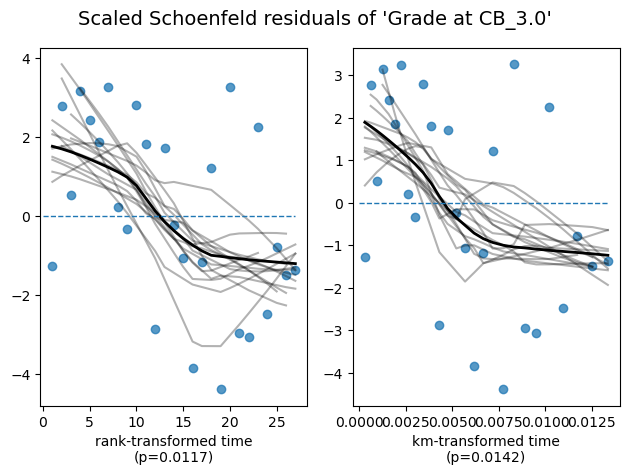


Neoadjuvant (Only) therapy with biological drugs (p = 0.0359)

   Bootstrapping lowess lines. May take a moment...



The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 3228 total observations, 3201 right-censored observations>
         test_name = proportional_hazard_test

---
                                                       test_statistic    p  -log2(p)
Adjuvant therapy using biological drugs          km              0.64 0.42      1.24
                                                 rank            0.66 0.42      1.27
Grade at CB_3.0                                  km              6.01 0.01      6.14
                                                 rank            6.36 0.01      6.42
Isotype at CB_4.0                                km              0.00 0.95      0.07
                                                 rank            0.03 0.86      0.21
Neoadjuvant (Only) therapy with biological drugs km              4.60 0.03      4.96
                                                 rank            4.40 0.04      4.80
Oestrogen receptor status at CB                  km              4.83 0.03      5.16
                                                 rank            3.68 0.05      4.19
Radiotherapy (RT) performed                      km              1.22 0.27      1.89
                                                 rank            1.25 0.26      1.93
Radiotherapy on supraclavicular area             km              0.01 0.92      0.13
                                                 rank            0.00 0.98      0.03
Side location of the lesion                      km              0.11 0.74      0.44
                                                 rank            0.19 0.67      0.59
Treatment in association with chemotherapy       km              0.48 0.49      1.04
                                                 rank            0.45 0.50      0.99



1. Variable 'Neoadjuvant (Only) therapy with biological drugs' failed the non-proportional test: p-value is 0.0320.

   Advice: with so few unique values (only 2), you can include `strata=['Neoadjuvant (Only) therapy
with biological drugs', ...]` in the call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



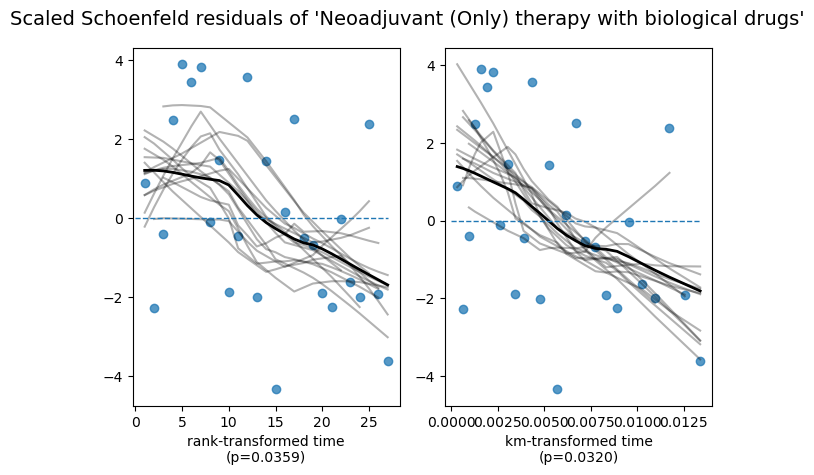

In [10]:
# Plot Schoenfeld residuals for terms with PH violations
if len(violations) > 0:
    print(f"Plotting Schoenfeld residuals for {len(violations)} terms with PH violations...\n")
    
    # Plot up to 12 most significant violations
    features_to_plot = violations.sort_values('p').head(12).index.tolist()
    
    for feature in features_to_plot:
        p_val = violations.loc[feature, 'p']
        print(f"\n{feature} (p = {p_val:.4f})")
        
        # Use check_assumptions which creates its own figure
        cph_retained.check_assumptions(df_retained, p_value_threshold=0.05, 
                             show_plots=True, columns=[feature])
        plt.show()
else:
    print("No PH violations detected - skipping residual plots")

## Global test

Test whether the retained terms, jointly, satisfy the PH assumption.

**Why not just sum the 9 per-term statistics above?** `lifelines.statistics.proportional_hazard_test`
(v0.30.0) only ever returns per-covariate univariate χ²(1) statistics - there's no
`_GLOBAL` row it can produce, in any version of this fit. Summing those 9 statistics and
comparing to χ²(9), like the previous version of this cell did across all 30 raw covariates,
isn't a valid joint test in general: Schoenfeld residuals of correlated covariates are
themselves correlated, so their marginal statistics aren't independent χ²(1) draws and their
sum isn't χ²(k) even asymptotically. (The ridge fit's severe collinearity also biased the sum
downward, per the note above, but summing would be invalid even without that.)

**Correct alternative:** a likelihood-ratio test against an extended Cox model that adds a
`covariate x log(time)` interaction for every retained term (Therneau & Grambsch, *Modeling
Survival Data*, ch. 6). This is a genuine nested-model LRT, so its null distribution really is
χ²(df) regardless of correlation between the covariates.

In [11]:
# Global proportional hazards test: likelihood-ratio test vs. an extended Cox
# model with a covariate x log(time) interaction added for every retained term.
from scipy.stats import chi2

df_extended = df_retained.copy()
log_time = np.log(df_extended['time'])
interaction_terms = []
for term in retained_terms:
    col = f"{term} x log(time)"
    df_extended[col] = df_extended[term] * log_time
    interaction_terms.append(col)

cph_extended = CoxPHFitter(penalizer=0.0)
cph_extended.fit(df_extended, duration_col='time', event_col='event')

lrt_stat = 2 * (cph_extended.log_likelihood_ - cph_retained.log_likelihood_)
lrt_df = len(interaction_terms)
global_p = chi2.sf(lrt_stat, lrt_df)

print("\n" + "="*80)
print("GLOBAL PROPORTIONAL HAZARDS TEST (likelihood-ratio, covariate x log(time))")
print("="*80)
print(f"Log-likelihood, retained-terms model:      {cph_retained.log_likelihood_:.4f}")
print(f"Log-likelihood, + time interactions:       {cph_extended.log_likelihood_:.4f}")
print(f"\nLRT statistic: {lrt_stat:.4f}   df: {lrt_df}   p-value: {global_p:.4f}")

print("\nPer-term interaction coefficients (large |coef|, small p => that term's")
print("hazard ratio is not constant over time):")
print(cph_extended.summary.loc[interaction_terms, ['coef', 'p']].sort_values('p'))

# Interpretation
print("\n" + "-"*80)
if global_p < 0.05:
    print("⚠️  RESULT: jointly, the retained terms VIOLATE the proportional hazards assumption.")
    print("\nRecommendations:")
    print("  1. Stratify by, or add explicit time-varying coefficients for, the")
    print("     term(s) with the most significant interaction p-value above")
    print("  2. Consider alternative models:")
    print("     - Accelerated Failure Time (AFT) models")
    print("     - Time-stratified Cox models")
    print("     - Machine learning survival models (RSF, GBM)")
else:
    print("✓ RESULT: jointly, the retained terms are consistent with the proportional hazards assumption.")

print("-"*80)

n_violations = len(violations)
n_terms = len(retained_terms)
pct_violations = 100 * n_violations / n_terms

print(f"\nSummary:")
print(f"  - Terms tested: {n_terms}")
print(f"  - Terms individually violating PH (p < 0.05): {n_violations} ({pct_violations:.1f}%)")
print(f"  - Joint LRT p-value: {global_p:.4f}")
print("="*80)


GLOBAL PROPORTIONAL HAZARDS TEST (likelihood-ratio, covariate x log(time))
Log-likelihood, retained-terms model:      -159.0460
Log-likelihood, + time interactions:       -151.5261

LRT statistic: 15.0398   df: 9   p-value: 0.0898

Per-term interaction coefficients (large |coef|, small p => that term's
hazard ratio is not constant over time):
                                                        coef         p
covariate                                                             
Neoadjuvant (Only) therapy with biological drug... -6.230457  0.000159
Grade at CB_3.0 x log(time)                        -0.994352  0.316459
Oestrogen receptor status at CB x log(time)         0.871798  0.408222
Radiotherapy on supraclavicular area x log(time)   -0.642415  0.454089
Isotype at CB_4.0 x log(time)                      -0.649797  0.542304
Side location of the lesion x log(time)            -0.308987  0.748640
Radiotherapy (RT) performed x log(time)            -0.243091  0.814754
Treatment in as

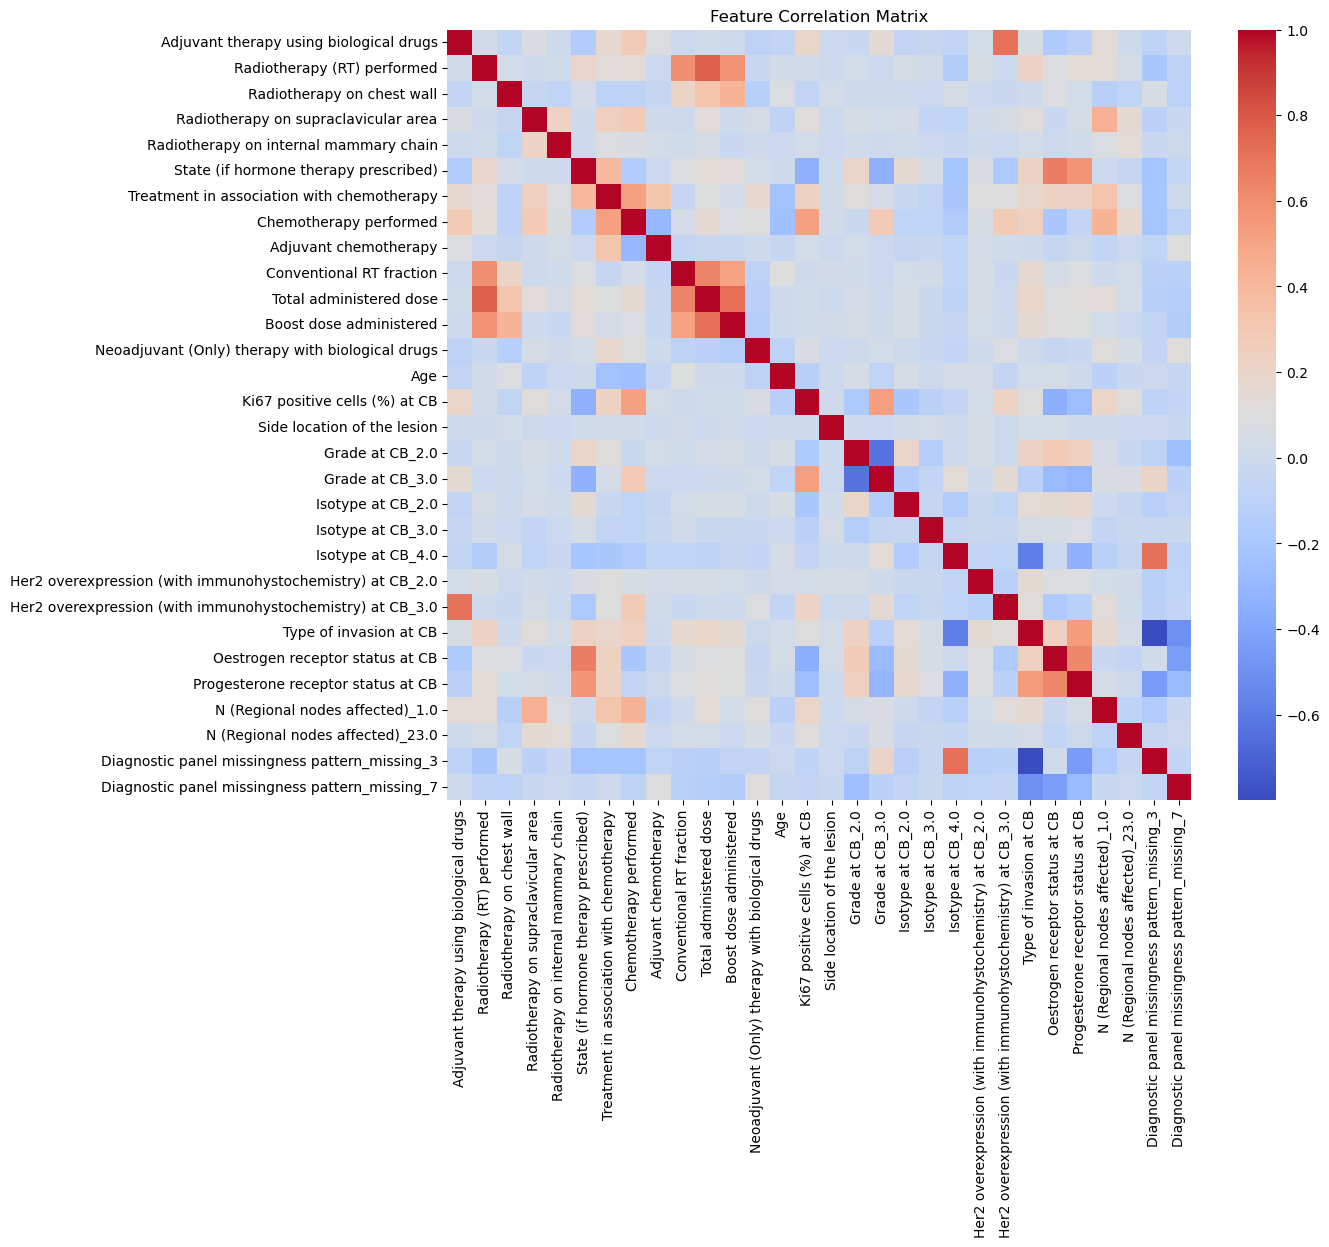

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming X is your feature dataframe
corr_matrix = data_x_scaled.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) 
                       for i in range(len(df.columns))]
    return vif_data.sort_values(by="VIF", ascending=False)

print(calculate_vif(data_x_scaled))

                                              feature        VIF
23                             Type of invasion at CB  41.602133
1                         Radiotherapy (RT) performed  25.648677
10                            Total administered dose  22.551811
24                    Oestrogen receptor status at CB  19.659069
5               State (if hormone therapy prescribed)  17.791150
2                          Radiotherapy on chest wall  11.846738
13                                                Age   9.752444
7                              Chemotherapy performed   9.044155
6          Treatment in association with chemotherapy   8.752464
11                            Boost dose administered   7.819677
25                 Progesterone receptor status at CB   7.754409
14                      Ki67 positive cells (%) at CB   6.588360
9                            Conventional RT fraction   6.362223
16                                    Grade at CB_2.0   6.245407
28     Diagnostic panel m

In [14]:
def reduce_vif(df, thresh=10.0):
    cols = df.columns.tolist()
    while True:
        vif = [variance_inflation_factor(df[cols].values, i) for i in range(len(cols))]
        max_vif = max(vif)
        if max_vif > thresh:
            max_idx = vif.index(max_vif)
            print(f"Dropping '{cols[max_idx]}' with VIF: {max_vif:.2f}")
            del cols[max_idx]
        else:
            break
    return df[cols]

data_x_reduced = reduce_vif(data_x_scaled)

Dropping 'Type of invasion at CB' with VIF: 41.60
Dropping 'Radiotherapy (RT) performed' with VIF: 23.27


Dropping 'Oestrogen receptor status at CB' with VIF: 18.51
Dropping 'Total administered dose' with VIF: 14.69


Dropping 'State (if hormone therapy prescribed)' with VIF: 11.81


In [15]:
def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) 
                       for i in range(len(df.columns))]
    return vif_data.sort_values(by="VIF", ascending=False)

print(calculate_vif(data_x_reduced))

                                              feature       VIF
1                          Radiotherapy on chest wall  8.717871
10                                                Age  7.440754
5                              Chemotherapy performed  6.215565
11                      Ki67 positive cells (%) at CB  6.163729
13                                    Grade at CB_2.0  5.791034
8                             Boost dose administered  5.369290
20                 Progesterone receptor status at CB  4.774653
7                            Conventional RT fraction  4.688918
4          Treatment in association with chemotherapy  4.669111
14                                    Grade at CB_3.0  3.990164
23     Diagnostic panel missingness pattern_missing_3  2.810133
0             Adjuvant therapy using biological drugs  2.611311
19  Her2 overexpression (with immunohystochemistry...  2.588972
17                                  Isotype at CB_4.0  2.582335
6                               Adjuvant